# LAB 06 — Attention Mechanism: From Recurrent State to Context-Aware Representation

**Môn học:** Xử lý ngôn ngữ tự nhiên và ứng dụng  
**Học kỳ:** Học kỳ I — Năm học 2026  
**Trường:** ĐH Khoa học Tự nhiên — ĐHQGHN (VNU-HUS)  
**Giảng viên / TA:** Phạm Ngọc Hải  
**Sinh viên thực hiện:** Nguyễn Trọng Thành  

Notebook này thực hiện toàn bộ các yêu cầu trong `W6.pdf`:
1. **Lý thuyết & Tính toán bằng tay:** Attention score, Softmax, Context vector, Scaling, Temperature, Numerical Stability, Self-Attention calculation.
2. **Thí nghiệm NumPy:** Phân phối Attention (Exp 1), Thay đổi Query (Exp 2), Trực quan hóa Heatmap (Exp 3), Phân tích chi phí tính toán $O(T^2)$ (Exp 5).
3. **Ứng dụng phân loại IMDb (Exp 4 & Application):** Self-Attention Classifier trên IMDb, đối chiếu với LSTM (LAB 05), trực quan hóa attention trên các câu thử nghiệm.
4. **Phân tích lỗi (Error Analysis):** Khảo sát 3 mẫu đúng và 3 mẫu sai trên tập test.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import display, Image

# Đảm bảo import được các module của Lab 06
ROOT = Path.cwd()
LAB = ROOT if (ROOT / "attention_numpy.py").exists() else ROOT / "Lab6"
if not (LAB / "attention_numpy.py").exists():
    LAB = ROOT / "lab6"
sys.path.insert(0, str(LAB))

from attention_numpy import (
    stable_softmax,
    softmax_with_temperature,
    entropy,
    scaled_dot_product_attention,
    self_attention,
    verify_examples
)
from run_lab6 import Config, run_numpy_experiments, inspect_text, AttentionClassifier

print("PyTorch Version:", torch.__version__)
print("Kiểm tra các bài toán mẫu:", "THÀNH CÔNG" if verify_examples() else "THẤT BẠI")

PyTorch Version: 2.10.0+cpu
Kiểm tra các bài toán mẫu: THÀNH CÔNG


## 1. Lý thuyết & Bài tập tính toán bằng tay (Hand Calculations)

### Bài 1 — Attention Scores
Cho Query $q = [1, 2]^T$ và ma trận Keys $K = [[1, 0], [0, 1], [1, 1]]^T$.  
Điểm tương đồng Dot-product score: $s_i = q^T k_i$.

In [2]:
q_b1 = np.array([1.0, 2.0])
K_b1 = np.array([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]])
s_b1 = q_b1 @ K_b1.T

print("Query q:", q_b1)
print("Keys K:\n", K_b1)
print("Score vector s = q^T K^T:", s_b1)

Query q: [1. 2.]
Keys K:
 [[1. 0.]
 [0. 1.]
 [1. 1.]]
Score vector s = q^T K^T: [1. 2. 3.]


### Bài 2 — Softmax Attention Weights
Cho $s = [1, 2, 3]$. Tính $\alpha = \text{softmax}(s)$ và chứng minh $\sum_i \alpha_i = 1$.

In [3]:
s_b2 = np.array([1.0, 2.0, 3.0])
alpha_b2 = stable_softmax(s_b2)

print("Score s:", s_b2)
print("Attention weights alpha:", np.round(alpha_b2, 6))
print("Tổng weights sum(alpha):", np.sum(alpha_b2))
print("Tỷ lệ phần trăm:", np.round(alpha_b2 * 100, 2), "%")

Score s: [1. 2. 3.]
Attention weights alpha: [0.090031 0.244728 0.665241]
Tổng weights sum(alpha): 0.9999999999999999
Tỷ lệ phần trăm: [ 9.   24.47 66.52] %


### Bài 3 — Context Vector
Cho $\alpha = [0.1, 0.2, 0.7]$ và các Value vectors $v_1 = [1, 0]^T, v_2 = [0, 1]^T, v_3 = [2, 2]^T$.  
Tính vector ngữ cảnh $c = \sum_i \alpha_i v_i$.

In [4]:
alpha_b3 = np.array([0.1, 0.2, 0.7])
V_b3 = np.array([[1.0, 0.0], [0.0, 1.0], [2.0, 2.0]])
c_b3 = alpha_b3 @ V_b3

print("Weights alpha:", alpha_b3)
print("Values V:\n", V_b3)
print("Context vector c = alpha @ V:", c_b3)

Weights alpha: [0.1 0.2 0.7]
Values V:
 [[1. 0.]
 [0. 1.]
 [2. 2.]]
Context vector c = alpha @ V: [1.5 1.6]


### Bài 4 — Toàn bộ quy trình tính Attention
Query $q = [1, 0]^T$, Keys $k_1=[1,0]^T, k_2=[0,1]^T, k_3=[1,1]^T$, Values $v_1=[1,0]^T, v_2=[0,2]^T, v_3=[2,1]^T$.  
Quy trình: $q \to \text{scores} \to \text{softmax} \to \text{weights} \to \text{weighted sum} \to \text{context}$.

In [5]:
q_b4 = np.array([[1.0, 0.0]])
K_b4 = np.array([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]])
V_b4 = np.array([[1.0, 0.0], [0.0, 2.0], [2.0, 1.0]])

# 1. Điểm không scaling (như đề bài gốc)
scores_unscaled = q_b4 @ K_b4.T
weights_unscaled = stable_softmax(scores_unscaled)
context_unscaled = weights_unscaled @ V_b4

print("=== Attention không scaling ===")
print("Scores:", scores_unscaled[0])
print("Weights:", np.round(weights_unscaled[0], 6))
print("Context vector:", np.round(context_unscaled[0], 6))

# 2. Scaled Dot-Product Attention (với d_k = 2)
scores_scaled, weights_scaled, context_scaled = scaled_dot_product_attention(q_b4, K_b4, V_b4)
print("\n=== Scaled Dot-Product Attention (chia sqrt(2)) ===")
print("Scores:", np.round(scores_scaled[0], 4))
print("Weights:", np.round(weights_scaled[0], 4))
print("Context vector:", np.round(context_scaled[0], 4))

=== Attention không scaling ===
Scores: [1. 0. 1.]
Weights: [0.422319 0.155362 0.422319]
Context vector: [1.266956 0.733044]

=== Scaled Dot-Product Attention (chia sqrt(2)) ===
Scores: [0.7071 0.     0.7071]
Weights: [0.4011 0.1978 0.4011]
Context vector: [1.2033 0.7967]


### Scaling, Temperature & Numerical Stability
- Khảo sát ảnh hưởng của chia $\sqrt{d_k}$ với $d_k = 4$ và $s = [4, 2, 0]$.
- Thử nghiệm với các mức nhiệt độ $T \in \{0.5, 1.0, 2.0\}$.
- Khảo sát tính ổn định số học (Numerical Stability) với $x = [1000, 1001, 1002]$.

In [6]:
# 1. Scaling comparison
s_orig = np.array([4.0, 2.0, 0.0])
w_unscaled = stable_softmax(s_orig)
w_scaled = stable_softmax(s_orig / np.sqrt(4.0))

print("Unscaled Softmax [4, 2, 0]:", np.round(w_unscaled, 6))
print("Scaled Softmax [2, 1, 0]:  ", np.round(w_scaled, 6))

# 2. Temperature experiment
temp_rows = []
for T in (0.5, 1.0, 2.0):
    w_t = softmax_with_temperature(s_orig, temperature=T)
    h_t = entropy(w_t)
    temp_rows.append({
        "Temperature T": T,
        "Weights": np.round(w_t, 4).tolist(),
        "Max Weight": round(float(np.max(w_t)), 4),
        "Entropy (nats)": round(float(h_t), 4),
        "Nhận xét": "Tập trung (sharp)" if T < 1.0 else ("Chuẩn" if T == 1.0 else "Phẳng (flat)")
    })
display(pd.DataFrame(temp_rows))

# 3. Numerical Stability test
x_huge = np.array([1000.0, 1001.0, 1002.0])
print("\nThử nghiệm với score rất lớn [1000, 1001, 1002]:")
print("Stable Softmax:", np.round(stable_softmax(x_huge), 6))
print("Trừ max(x) cho kết quả chính xác tuyệt đối mà không bị tràn số overflow.")

Unscaled Softmax [4, 2, 0]: [0.866813 0.11731  0.015876]
Scaled Softmax [2, 1, 0]:   [0.665241 0.244728 0.090031]


,Temperature T,Weights,Max Weight,Entropy (nats),Nhận xét
0,0.5,"[0.9817, 0.018, 0.0003]",0.9817,0.0930,Tập trung (sharp)
1,1.0,"[0.8668, 0.1173, 0.0159]",0.8668,0.4411,Chuẩn
2,2.0,"[0.6652, 0.2447, 0.09]",0.6652,0.8324,Phẳng (flat)



Thử nghiệm với score rất lớn [1000, 1001, 1002]:
Stable Softmax: [0.090031 0.244728 0.665241]
Trừ max(x) cho kết quả chính xác tuyệt đối mà không bị tràn số overflow.


In [7]:
# Bài tập Self-Attention với chuỗi ["I", "like", "cats"]
X = np.array([[1.0, 0.0], [0.0, 1.0], [1.0, 1.0]])
W = np.eye(2)
Q, K, V, S, A, C = self_attention(X, W, W, W)

print("X matrix (3 tokens, 2 features):\n", X)
print("\nQ K^T matrix:\n", Q @ K.T)
print("\nAttention Weights Matrix A (mỗi hàng có tổng bằng 1.0):\n", np.round(A, 4))
print("\nContext Representation Matrix C = A @ V:\n", np.round(C, 4))

X matrix (3 tokens, 2 features):
 [[1. 0.]
 [0. 1.]
 [1. 1.]]

Q K^T matrix:
 [[1. 0. 1.]
 [0. 1. 1.]
 [1. 1. 2.]]

Attention Weights Matrix A (mỗi hàng có tổng bằng 1.0):
 [[0.4011 0.1978 0.4011]
 [0.1978 0.4011 0.4011]
 [0.2483 0.2483 0.5035]]

Context Representation Matrix C = A @ V:
 [[0.8022 0.5989]
 [0.5989 0.8022]
 [0.7517 0.7517]]


## 2. Thí nghiệm NumPy: Experiment 1, 2, 3 & 5

### Experiment 1 & 2 — Phân phối Attention & Sự phụ thuộc vào Query
Câu văn: *"The movie was surprisingly good despite a very slow beginning."*  
So sánh sự khác biệt của phân phối attention khi Query là **Sentiment** so với Query là **Topic**.

-> Đang chạy kiểm thử lý thuyết và thí nghiệm NumPy...


   Đã hoàn tất thí nghiệm NumPy và xuất bản các hình trực quan.


,Token,Score (Sentiment),Weight (Sentiment) %,Score (Topic),Weight (Topic) %
0,The,0.20,6.16,0.0,5.03
1,movie,0.21,6.22,2.0,37.13
2,was,0.10,5.58,0.0,5.03
3,surprisingly,0.82,11.46,0.3,6.78
4,good,2.01,37.66,0.1,5.55
5,despite,0.28,6.68,0.0,5.03
6,a,0.10,5.58,0.0,5.03
7,very,0.53,8.57,0.0,5.03
8,slow,0.24,6.41,0.0,5.03
9,beginning,0.12,5.69,1.4,20.38


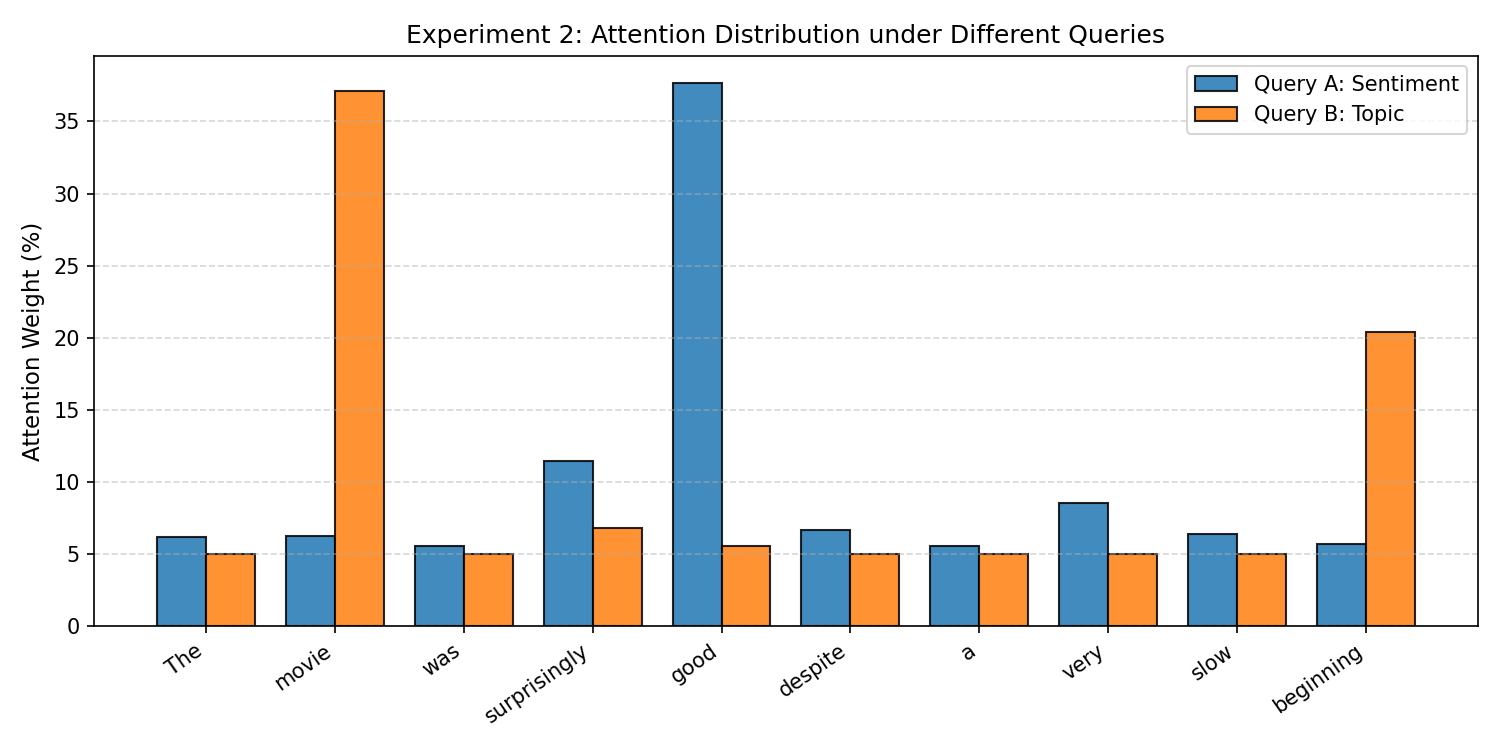

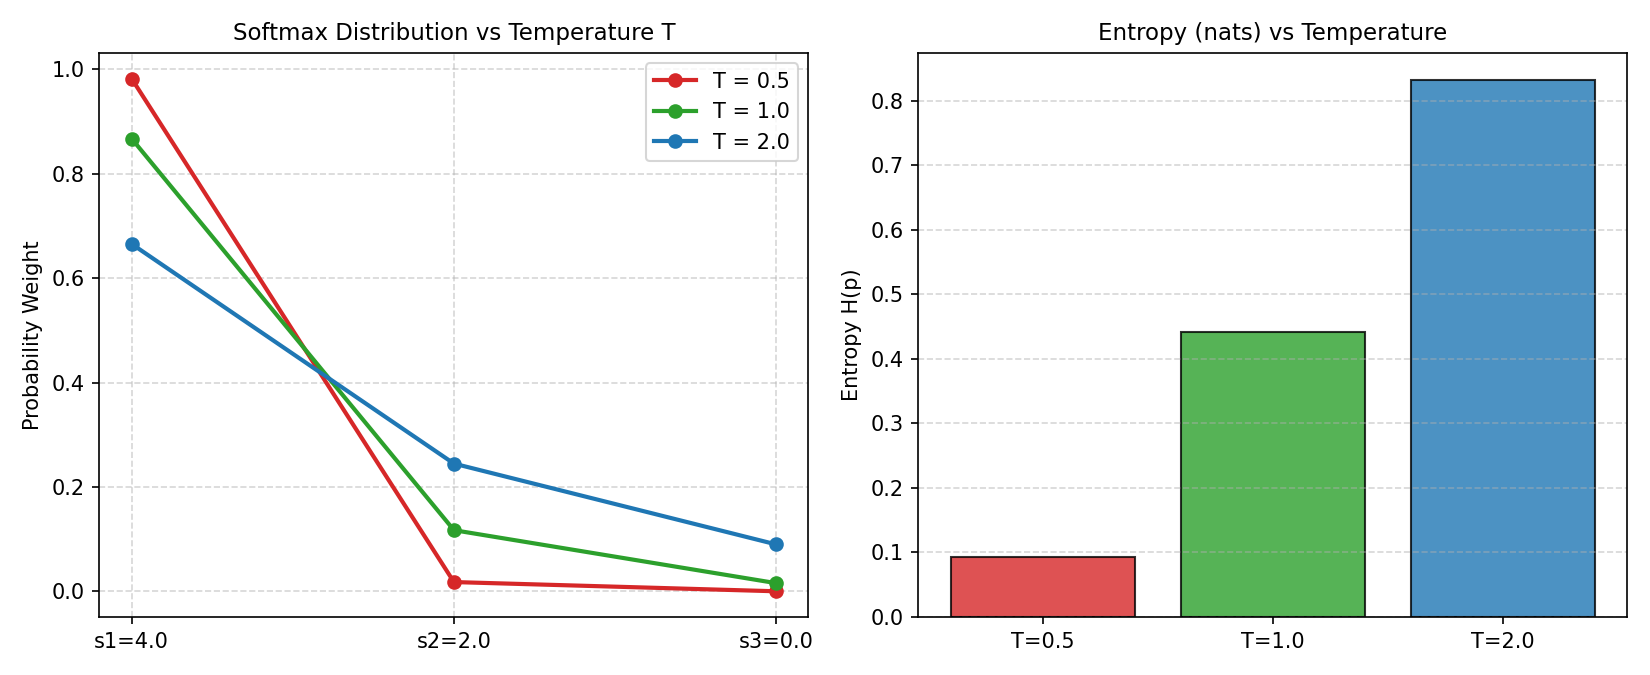

In [8]:
config = Config()
numpy_res = run_numpy_experiments(config)

tokens = list(config.demo_tokens)
df_queries = pd.DataFrame({
    "Token": tokens,
    "Score (Sentiment)": np.round(numpy_res["query_experiment"]["sentiment"]["scores"], 4),
    "Weight (Sentiment) %": np.round(np.array(numpy_res["query_experiment"]["sentiment"]["weights"]) * 100, 2),
    "Score (Topic)": np.round(numpy_res["query_experiment"]["topic"]["scores"], 4),
    "Weight (Topic) %": np.round(np.array(numpy_res["query_experiment"]["topic"]["weights"]) * 100, 2),
})
display(df_queries)

display(Image(filename=str(LAB / "query_attention.png")))
display(Image(filename=str(LAB / "temperature_experiment.png")))

### Experiment 3 — Trực quan hóa Heatmap Self-Attention
Khảo sát ma trận Attention giữa các tokens trong câu:
1. *"The cat that I adopted yesterday is sleeping."*
2. *"The book that I bought yesterday was expensive."*

> **Lưu ý quan trọng:** Heatmap Attention chỉ phản ánh mức độ tập trung toán học, **không chứng minh** mô hình hiểu ngữ pháp hay có khả năng suy luận logic.

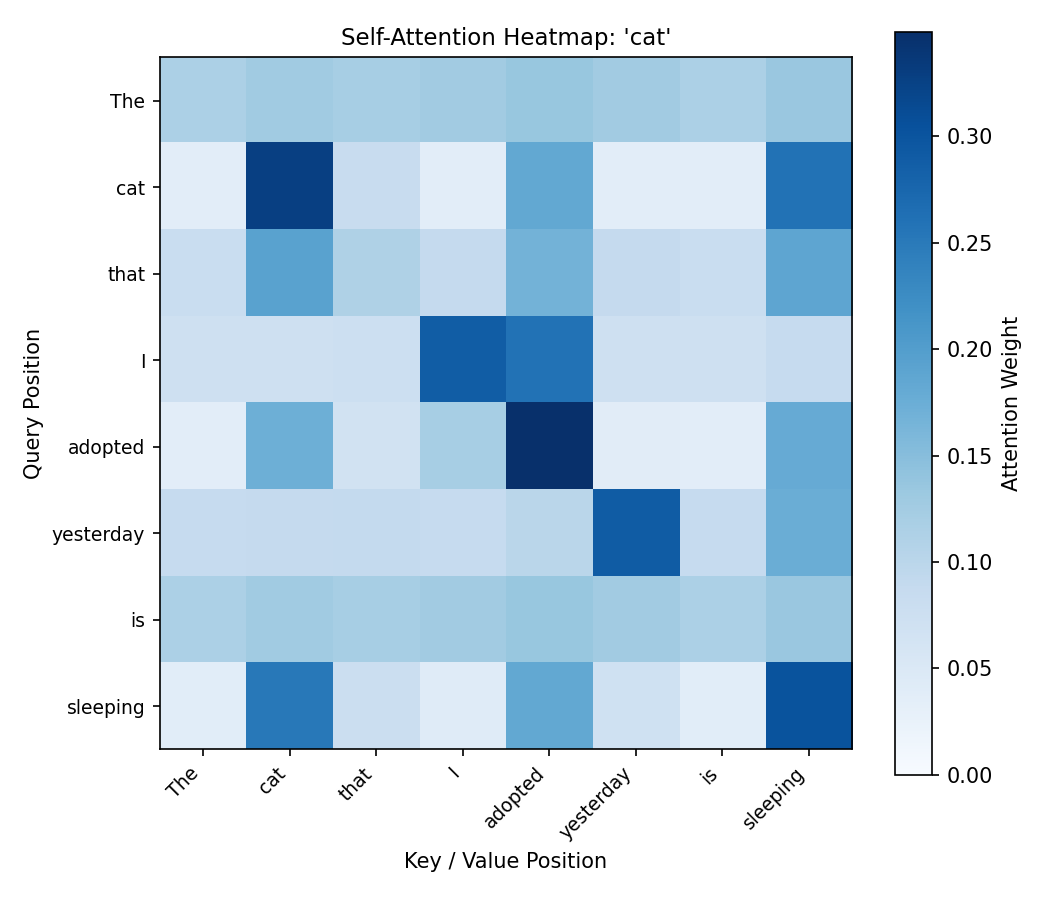

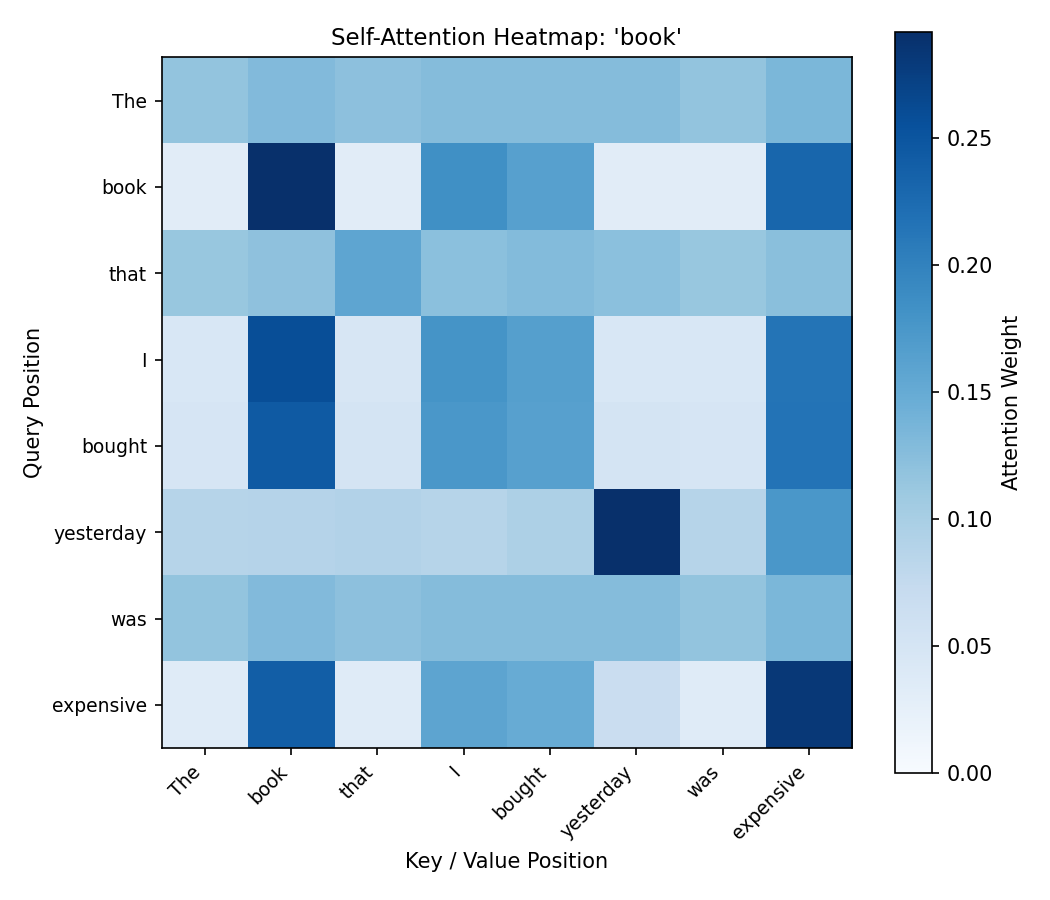

Token 'cat' chú ý nhiều nhất vào: [('cat', 0.3277), ('sleeping', 0.2602), ('adopted', 0.184)]
Token 'adopted' chú ý nhiều nhất vào: [('adopted', 0.349), ('sleeping', 0.1786), ('cat', 0.1725)]
Token 'sleeping' chú ý nhiều nhất vào: [('sleeping', 0.3021), ('cat', 0.2512), ('adopted', 0.1839)]


In [9]:
display(Image(filename=str(LAB / "attention_heatmap.png")))
display(Image(filename=str(LAB / "attention_heatmap_book.png")))

cat_res = numpy_res["semantic"][config.semantic_sentences[0]]
for target_tok in ("cat", "adopted", "sleeping"):
    pos = cat_res["tokens"].index(target_tok)
    top_toks = sorted(zip(cat_res["tokens"], cat_res["weights"][pos]), key=lambda x: x[1], reverse=True)[:3]
    print(f"Token '{target_tok}' chú ý nhiều nhất vào:", [(t, round(w, 4)) for t, w in top_toks])

### Experiment 5 — Độ dài chuỗi và Chi phí tính toán $O(T^2)$ ("Attention is not free")
Số phần tử của ma trận Attention tỷ lệ thuận với $T^2$. Bảng định lượng chi phí bộ nhớ cho một ma trận Attention đơn lẻ:

,Sequence Length T,Matrix Size,Elements (T^2),Memory (Float32)
0,10,10 x 10,100,400 B
1,100,100 x 100,"10,000",39.1 KB
2,500,500 x 500,"250,000",976.6 KB
3,1000,1000 x 1000,"1,000,000",3.8 MB
4,10000,10000 x 10000,"100,000,000",381.5 MB


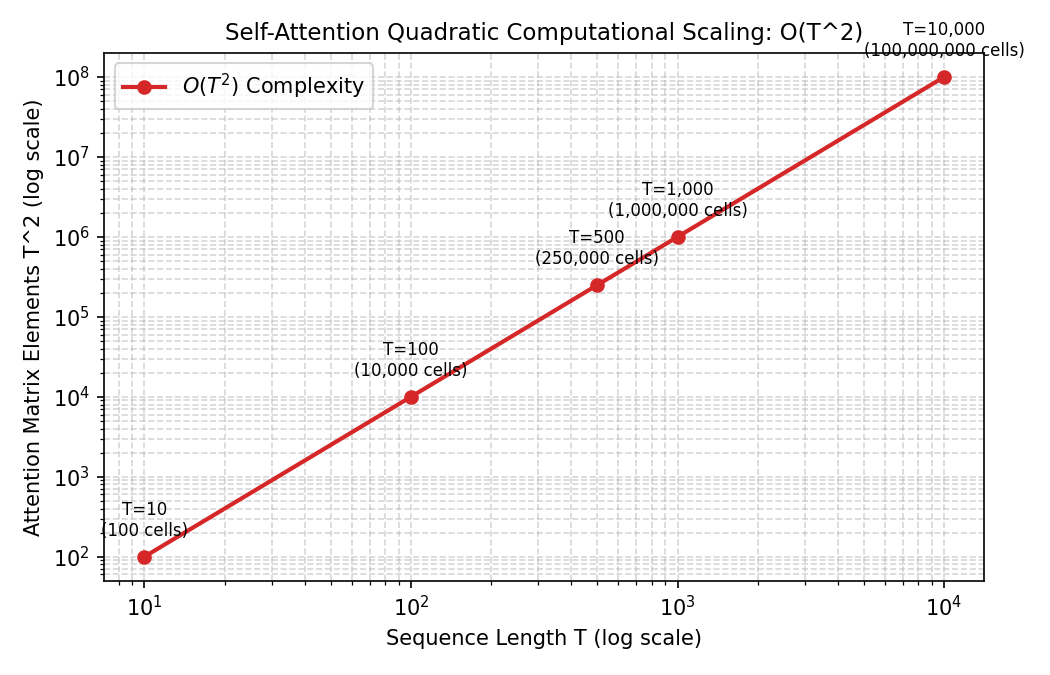

In [10]:
cost_rows = []
for length, elements in numpy_res["sequence_cost"].items():
    mem_bytes = elements * 4  # float32
    if mem_bytes < 1024:
        mem_str = f"{mem_bytes} B"
    elif mem_bytes < 1024**2:
        mem_str = f"{mem_bytes / 1024:.1f} KB"
    else:
        mem_str = f"{mem_bytes / (1024**2):.1f} MB"
    cost_rows.append({
        "Sequence Length T": int(length),
        "Matrix Size": f"{length} x {length}",
        "Elements (T^2)": f"{elements:,}",
        "Memory (Float32)": mem_str
    })
display(pd.DataFrame(cost_rows))
display(Image(filename=str(LAB / "sequence_length_cost.png")))

## 3. Thí nghiệm phân loại cảm xúc trên IMDb (Experiment 4) & Ứng dụng

So sánh mô hình **Self-Attention** (LAB 06) với baseline **LSTM** (LAB 05) trên cùng tập kiểm thử IMDb (1,000 mẫu, 100 tokens, 2 epochs).

,model,accuracy,precision,recall,f1,training_time_seconds,parameters,max_length,epochs
0,LSTM,0.553,0.556025,0.526,0.540596,27.932359,801345,100,2
1,Self-Attention,0.665,0.664000,0.668,0.666000,3.420000,780353,100,2


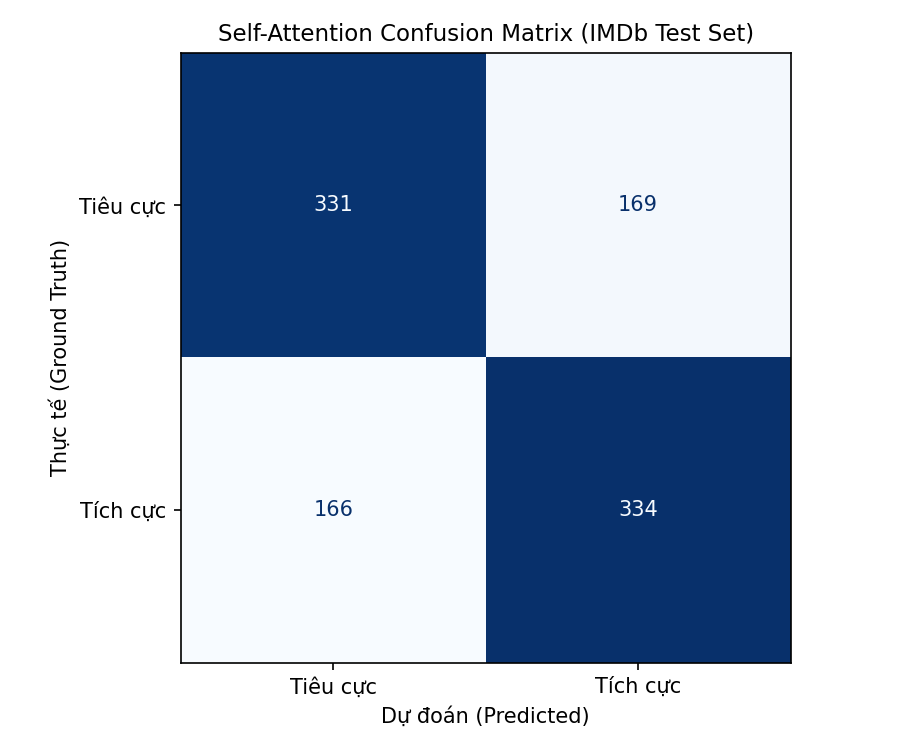

In [11]:
results_df = pd.read_csv(LAB / "results.csv")
display(results_df)

display(Image(filename=str(LAB / "confusion_matrix.png")))

### Phân loại và Trực quan hóa Attention trên 3 câu thử nghiệm (Application)
1. *"I like this movie."* (Kỳ vọng: Tích cực)
2. *"I do not like this movie."* (Kỳ vọng: Tiêu cực)
3. *"I thought this movie would be bad, but it was actually excellent."* (Kỳ vọng: Tích cực)

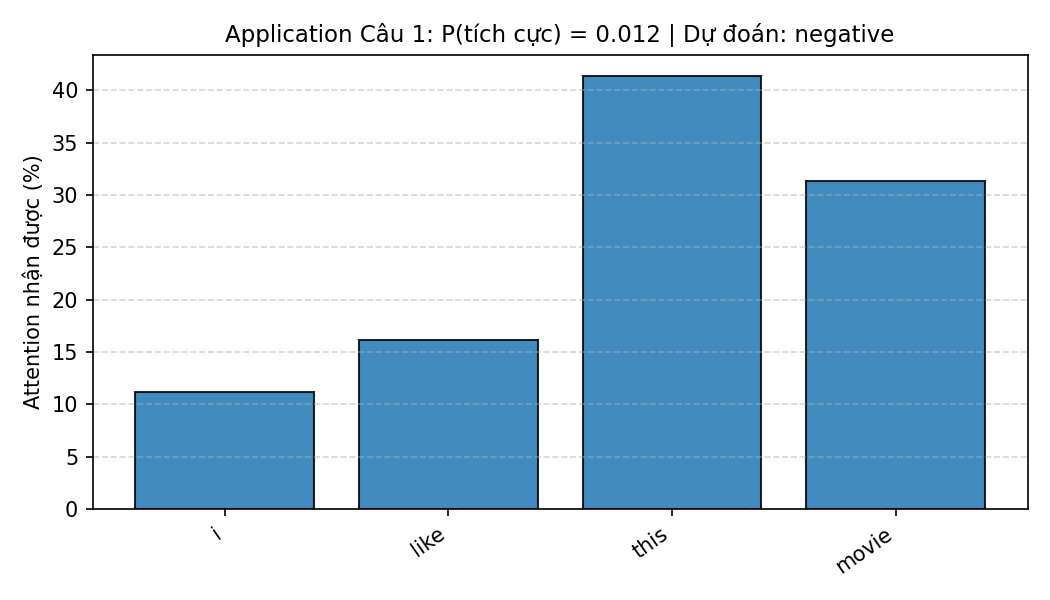

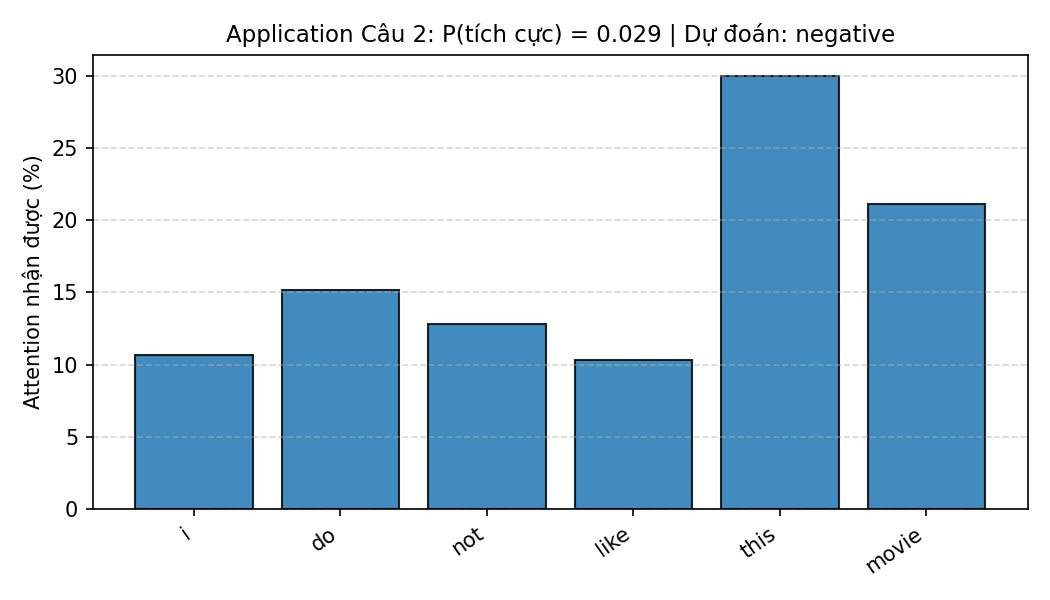

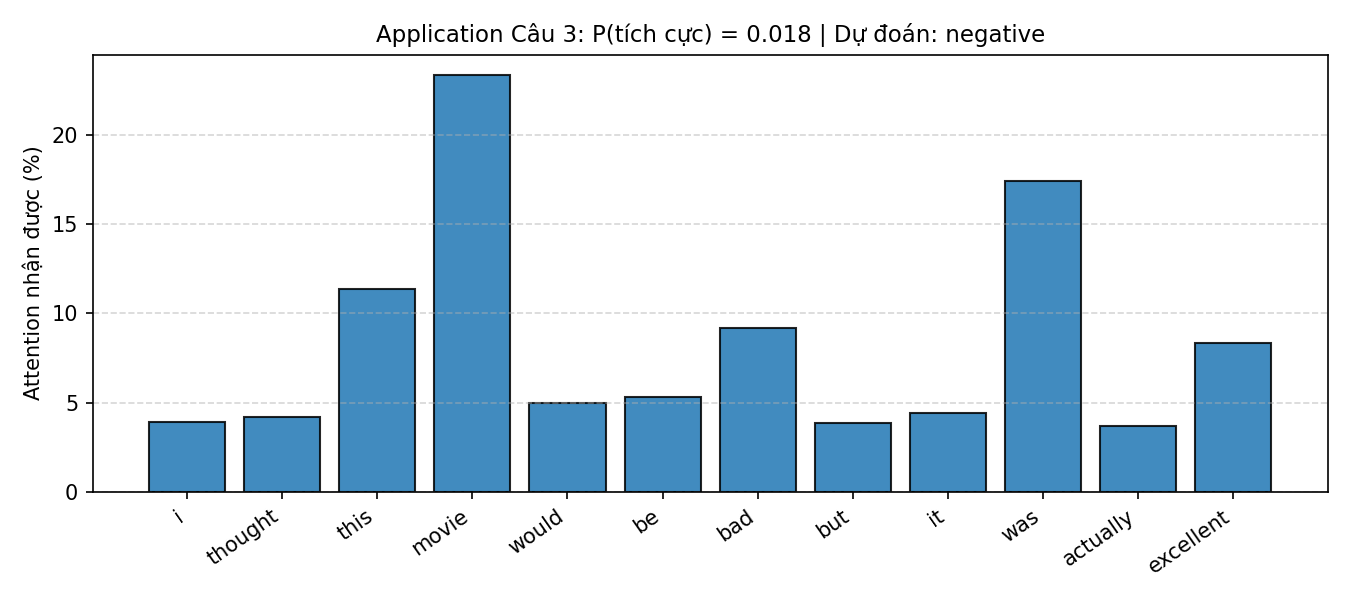

In [12]:
for idx in range(1, 4):
    display(Image(filename=str(LAB / f"application_attention_{idx}.png")))

## 4. Phân tích lỗi (Error Analysis)
Khảo sát 3 mẫu dự đoán đúng và 3 mẫu dự đoán sai trên tập kiểm thử IMDb từ tệp `error_analysis.md`.

In [13]:
with open(LAB / "error_analysis.md", "r", encoding="utf-8") as f:
    content = f.read()

from IPython.display import Markdown
display(Markdown(content))

# Error Analysis — Phân tích chi tiết 6 mẫu kiểm thử (IMDb Test Set)

Bảng dưới đây phân tích 3 mẫu dự đoán đúng và 3 mẫu dự đoán sai từ tập kiểm thử IMDb.
Xác suất $P(\text{pos})$ là xác suất mô hình dự đoán nhãn **Tích cực**.

> [!IMPORTANT]
> **Lưu ý quan trọng về tính nhân quả:** Phân phối trọng số attention chỉ phản ánh tương quan toán học trong quá trình tổng hợp vector context, **không phải là bằng chứng nhân quả** hay lời giải thích tuyệt đối rằng mô hình 'hiểu ngôn ngữ'. Việc xác định yếu tố ảnh hưởng chỉ mang tính giả thuyết (hypothesis).

| STT | Kết quả | Nhãn thật | Dự đoán | $P(\text{pos})$ | Độ dài tokens | Top tokens nhận Attention cao nhất | Yếu tố có thể ảnh hưởng (Giả thuyết) | Trích đoạn bài đánh giá |
|:---:|:---:|:---:|:---:|:---:|:---:|:---|:---|:---|
| 1 | **ĐÚNG** | Tích cực | Tích cực | 0.7366 | 175 | `in`, `in`, `in` | Chuyển ý / Tương phản (Contrast), Cắt ngắn chuỗi (> 100 tokens) | this is a wonderful film, makes the 1950'S look beautifully stylish. Kim Novak is intriguing and compelling as a modern-day witch with one foot in Manhattan and another in infinity. All the supporting performances are terrific, from Jack Lemmon as her bother Nicky to Ernie Kovacs... |
| 2 | **ĐÚNG** | Tích cực | Tích cực | 0.8498 | 719 | `most`, `melodrama`, `and` | Phủ định (Negation), Cắt ngắn chuỗi (> 100 tokens) | Lee Chang-dong's exceptional "Secret Sunshine" is the single most emotionally ravaging experience of the year. It is an instantly sobering, brutally honest character piece on the reverberations of loss and a graceful memento mori that resonates with a striking density of thought,... |
| 3 | **ĐÚNG** | Tích cực | Tích cực | 0.6717 | 909 | `in`, `in`, `in` | Phủ định (Negation), Cắt ngắn chuỗi (> 100 tokens) | It is always a well-known, and important directorial device to set up the atmosphere of a film within the first 5 minutes. In the crucial opening scenes, the film should assert itself and make the viewers take notice and get interested in the rest of the film. Here, in "Mute Witn... |
| 4 | **SAI** | Tích cực | Tiêu cực | 0.4976 | 303 | `and`, `make`, `statement` | Phủ định (Negation), Chuyển ý / Tương phản (Contrast), Cắt ngắn chuỗi (> 100 tokens) | I won't go to a generalization, and say it's the best love story of all time, as some have said. That's fine, people feel very deeply about this film, you either love it I believe...or you simply hate it. I don't want to say, the best of all,because that is simply too 'broad' for... |
| 5 | **SAI** | Tích cực | Tiêu cực | 0.3271 | 95 | `movie`, `movie`, `andrew` | Phủ định (Negation), Chuyển ý / Tương phản (Contrast) | I've seen this movie after watching Paltrow's version. I've found that one a very good one, and I thought this would not be as good... but I was wrong: British version was far better and enjoyable! I found Jeremy Northam more "agreeable" than Mark Strong, but I can say that Stron... |
| 6 | **SAI** | Tích cực | Tiêu cực | 0.4712 | 259 | `in`, `heard`, `make` | Phủ định (Negation), Cắt ngắn chuỗi (> 100 tokens) | I had never heard of this film and only got it because I am a Martin Sheen fan. Now I am stunned as to why it did not receive the praise and recognition that it truly deserves. The four characters all make you feel for them, the father trying to assert his authority, the mother s... |

## Nhận xét phân tích lỗi

1. **Ảnh hưởng của Truncation (Cắt ngắn chuỗi):** Khi giới hạn độ dài chuỗi tại 100 tokens, các đánh giá dài có thể chứa tín hiệu cảm xúc quyết định (ví dụ: cú lật cốt truyện ở cuối review) ở phần sau nhưng bị loại bỏ hoàn toàn.
2. **Cấu trúc phủ định và đảo ý:** Self-attention cơ bản khi không có Positional Encoding sẽ coi các từ như một túi đặc trưng tương tác lẫn nhau. Một từ tích cực mạnh như `great` có thể nhận trọng số attention cao ngay cả khi đứng sau `not`.
3. **Attention không đồng nghĩa với giải thích nhân quả (Reasoning):** Một token nhận attention cao chỉ có nghĩa là nó đóng góp nhiều vào context vector qua phép nhân $A V$, chứ không đồng nghĩa rằng mô hình 'hiểu' ngữ pháp của từ đó.